In [120]:
# libraries 
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn import metrics                           
from sklearn import tree
from sklearn.model_selection import train_test_split

In [121]:
data_maternal= pd.read_csv("Maternal Health Risk Data Set.csv")
data_maternal.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [122]:
# Display number of rows and columns
data_maternal.shape

(1014, 7)

In [123]:
data_maternal.isnull().sum()

Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64

In [124]:
data_maternal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB


RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64


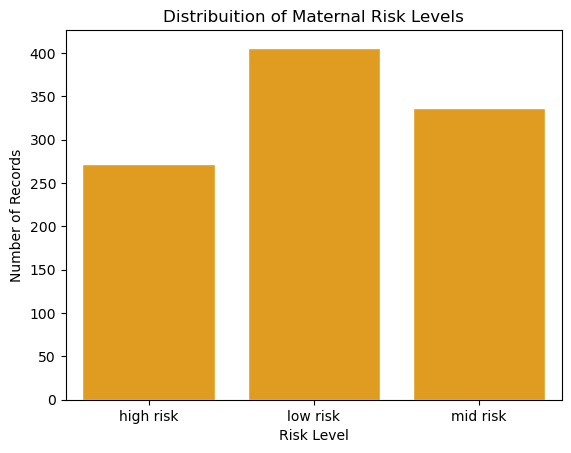

In [125]:
print (data_maternal["RiskLevel"].value_counts())
sns.countplot(data=data_maternal, x="RiskLevel",color="Orange",edgecolor="white")

plt.title("Distribuition of Maternal Risk Levels")
plt.xlabel("Risk Level")
plt.ylabel("Number of Records")

plt.show()

In [126]:
feature_cols = ['SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate','Age']
X = data_maternal[feature_cols]               
y = data_maternal['RiskLevel']                      # Target variable of the dataset

# Display the X and y arrays
print(X, y)

      SystolicBP  DiastolicBP    BS  BodyTemp  HeartRate  Age
0            130           80  15.0      98.0         86   25
1            140           90  13.0      98.0         70   35
2             90           70   8.0     100.0         80   29
3            140           85   7.0      98.0         70   30
4            120           60   6.1      98.0         76   35
...          ...          ...   ...       ...        ...  ...
1009         120           60  15.0      98.0         80   22
1010         120           90  18.0      98.0         60   55
1011          85           60  19.0      98.0         86   35
1012         120           90  18.0      98.0         70   43
1013         120           65   6.0     101.0         76   32

[1014 rows x 6 columns] 0       high risk
1       high risk
2       high risk
3       high risk
4        low risk
          ...    
1009    high risk
1010    high risk
1011    high risk
1012    high risk
1013     mid risk
Name: RiskLevel, Length: 1014, dt

In [127]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1) # 70% training and 30% test

X.shape, y.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1014, 6), (1014,), (709, 6), (305, 6), (709,), (305,))

In [128]:
# Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion='gini', max_depth = 4, random_state = 0)

# Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

In [129]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 0.6622950819672131
Accuracy: 0.66


In [130]:
X.columns.tolist()

['SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate', 'Age']

In [132]:
data_maternal['RiskLevel'].unique().tolist()

['high risk', 'low risk', 'mid risk']

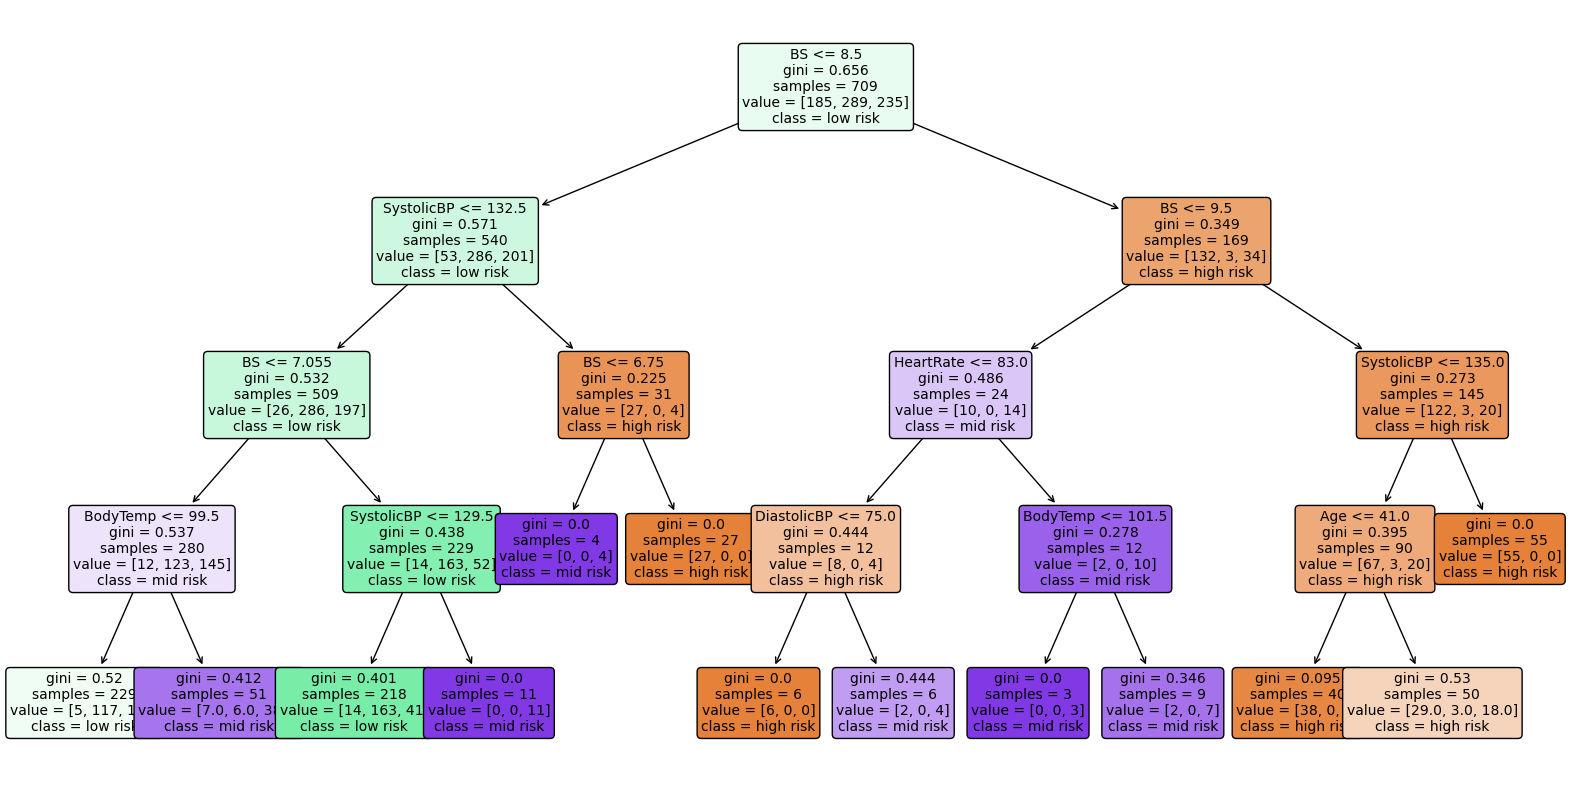

In [133]:
# Plot the Decision Tree
plt.figure(figsize=(20, 10))
plot_tree(clf, filled=True, feature_names=X.columns.tolist(), class_names=[str(label) for label in data_maternal['RiskLevel'].unique()], rounded=True, fontsize=10)
plt.show()

In [49]:
#Define X and y 
X = data_maternal.drop("RiskLevel", axis=1)
y = data_maternal["RiskLevel"]

In [40]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(random_state=42)

svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])

In [15]:
results = []
for test_size in [0.05, 0.15, 0.25]:

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    for name, model in [("Random Forest", rf), ("SVM", svm)]:

        scores = cross_val_score(
            model, X_train, y_train,
            cv=5,
            scoring="accuracy"
        )

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        accuracy = accuracy_score(y_test, predictions)

        results.append({
            "Test Size": test_size,
            "Model": name,
            "CV Mean Accuracy": scores.mean(),
            "Test Accuracy": accuracy
        })

results_df = pd.DataFrame(results)
print(results_df)

   Test Size          Model  CV Mean Accuracy  Test Accuracy
0       0.05  Random Forest          0.825567       0.784314
1       0.05            SVM          0.700928       0.686275
2       0.15  Random Forest          0.842015       0.843137
3       0.15            SVM          0.697977       0.705882
4       0.25  Random Forest          0.818421       0.874016
5       0.25            SVM          0.686842       0.716535


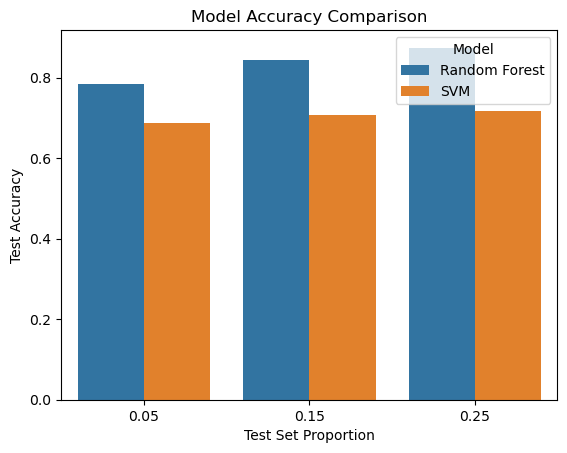

In [16]:
sns.barplot(
    data=results_df,
    x="Test Size",
    y="Test Accuracy",
    hue="Model"
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Test Accuracy")
plt.xlabel("Test Set Proportion")
plt.show()